In [ ]:
import sys

import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, "..")  # repo root, so `core` is importable

from core import deepc, drmpc
from core.cartpole import cartpole
from core.generate_rng import trial_rngs
from core.offline import collect_offline_trajectories
from core.radius import estimate_radius

## Setup: SAAMPC vs. DRMPC vs. DeePC on the linearized cart-pole

Same system, spec and data as `drmpc/cart_pole_experiment.ipynb`. All three methods see the **same offline trajectories** and the **same closed-loop noise** in each trial, via `trial_rngs(SEED, k)`.

| | Predicts with | Handles noise with |
|---|---|---|
| SAAMPC | least-squares L̂ + residual scenarios | nothing (radius 0) |
| DRMPC | least-squares L̂ + residual scenarios | Wasserstein radius (Algorithm 1) |
| DeePC | the trajectories themselves, blended by g (Page matrix, T_ini = 1) | λ_g‖g‖₁ (paper eq. 8) |

DeePC uses hard state bounds plus a slack instead of CVaR constraints. The slack weight is 1e3 for all three methods.

In [ ]:
A, B = cartpole()
n, m = A.shape[0], B.shape[1]
T = 20
STEPS = 50
NOISE = 0.01
SEED = 0       # evaluation trials, same as the DRMPC notebook
TUNE_SEED = 1  # lambda_g is chosen on these trials only, never on SEED
X0 = [0.9, 0.0, 0.0, 0.0]
WALL, TARGET = 1.0, 2.0
spec = dict(state_weight=[1, 0.1, 1, 0.1], ref=[TARGET, 0, 0, 0],
            x_min=[-np.inf, -np.inf, -0.15, -np.inf], x_max=[WALL, np.inf, 0.15, np.inf]) # Small angle limit added [-0.15 to 0.15]
SIZES = [35, 60, 100, 135]
COLORS = {"SAAMPC": "#2a78d6", "DRMPC": "#eb6834", "DeePC": "#3a9e5c"}


def dataset(num_trajectories, rng):
    return collect_offline_trajectories(A, B, num_trajectories, T, noise_std=NOISE,
                                        action_std=5.0, x0_std=0.05, rng=rng)


def closed_loop(make, W):
    """Run make() from X0 under W; None if a solve fails."""
    try:
        return drmpc.simulate(A, B, make(), X0, W)
    except RuntimeError:
        return None


def run_drmpc(L_hat, Z, Y, eps1, eps2, W):
    return closed_loop(lambda: drmpc.make_controller(L_hat, Z, Y, n, m, eps1, eps2,
                                                     u_max=10, slack_weight=1e3, **spec), W)


def run_deepc(Z, Y, lambda_g, W):
    return closed_loop(lambda: deepc.make_controller(Z, Y, n, lambda_g,
                                                      u_max=10, slack_weight=1e3, **spec), W)


def metrics(result):
    return (np.nan, np.nan) if result is None else drmpc.closed_loop_metrics(result[0], **spec)

## Data check: does the fundamental lemma hold?

DeePC needs rank [X0; U_f] = n + mT = 24, so every (x_0, u) direction is covered by some blend of trajectories.

In [ ]:
for N in SIZES:
    Z, _ = dataset(N, trial_rngs(SEED, 0)[0])
    rank, needed = deepc.fundamental_lemma_rank(Z) # If this is not satisfied, u can be forced to 0.
    print(f"N={N:<3}: rank {rank} of {needed} needed, {N - needed} spare columns")

N=35 : rank 24 of 24 needed, 11 spare columns
N=60 : rank 24 of 24 needed, 36 spare columns
N=100: rank 24 of 24 needed, 76 spare columns
N=135: rank 24 of 24 needed, 111 spare columns


## Choosing λ_g on a separate seed

λ_g has no formula like DRMPC's Algorithm 1, so it is picked from a grid on `TUNE_SEED` trials. Picking it on the evaluation trials would let DeePC fit their noise, which is the backtest in-sample bias from finance.

Rule: fewest mean violations, then lowest median cost. A λ_g with any failed run is excluded.

In [4]:
LAMBDAS = [0.01, 0.03, 0.1, 0.3, 1.0, 3.0]
TUNE_TRIALS = 5

tuning = {}
for N in SIZES:
    draws = []
    for trial in range(TUNE_TRIALS):
        rng_data, rng_noise = trial_rngs(TUNE_SEED, trial)
        draws.append((*dataset(N, rng_data), rng_noise.normal(0, NOISE, (STEPS, n))))
    for lam in LAMBDAS:
        tuning[N, lam] = np.array([metrics(run_deepc(Z, Y, lam, W)) for Z, Y, W in draws])


def score(r):
    costs, violations = r.T
    return (np.inf, np.inf) if np.isnan(costs).any() else (violations.mean(), np.median(costs))


LAMBDA_G = {N: min(LAMBDAS, key=lambda lam: score(tuning[N, lam])) for N in SIZES}

print("mean violations / median cost on tuning trials")
print("lambda_g " + "".join(f"{f'N={N}':>14}" for N in SIZES))
for lam in LAMBDAS:
    row = "".join(f"{'%.1f / %.1f' % score(tuning[N, lam]):>14}" for N in SIZES)
    print(f"{lam:<9}{row}")
print("chosen:", LAMBDA_G)

mean violations / median cost on tuning trials
lambda_g           N=35          N=60         N=100         N=135
0.01        22.0 / 60.7   17.0 / 61.3   15.6 / 61.2   10.4 / 57.8
0.03        21.2 / 59.4   20.0 / 61.4   15.6 / 60.2   10.8 / 59.1
0.1         17.6 / 59.3   19.6 / 60.5   17.4 / 60.9   16.2 / 60.1
0.3         16.4 / 59.2   21.8 / 67.1   10.6 / 57.2   17.4 / 59.4
1.0         17.8 / 57.5   27.8 / 72.6   11.6 / 58.8   18.8 / 64.7
3.0         19.8 / 60.6   21.6 / 59.1   10.6 / 57.8   20.8 / 65.9
chosen: {35: 0.3, 60: 0.01, 100: 0.3, 135: 0.01}


## One dataset: all three trajectories

N = 135, trial 0. Same data and noise for all three. Dashed lines are the bounds.

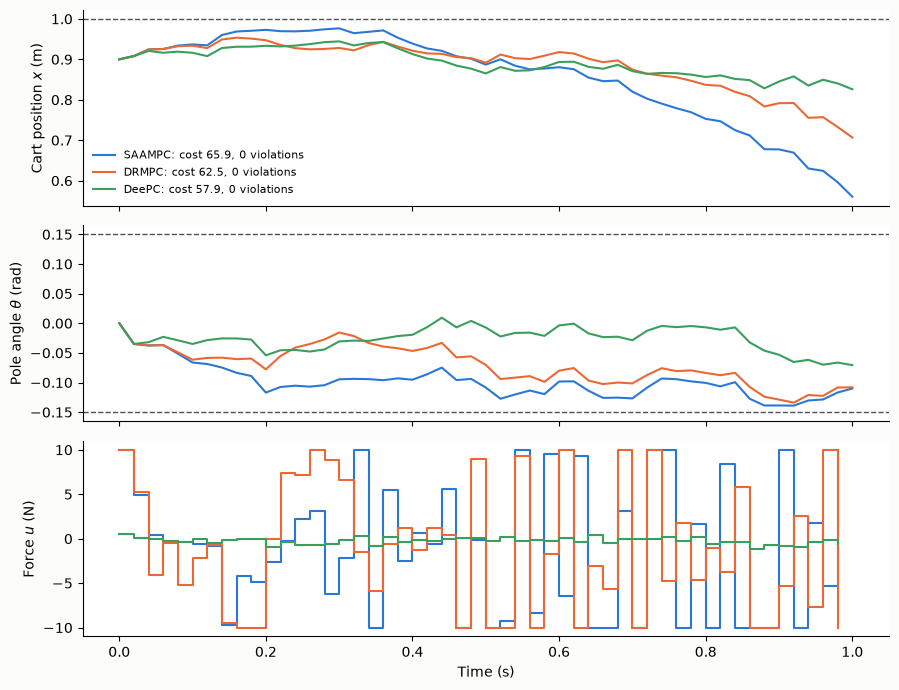

In [5]:
rng_data, rng_noise = trial_rngs(SEED, 0)
Z, Y = dataset(135, rng_data)
W = rng_noise.normal(0, NOISE, (STEPS, n))
L_hat, eps1, eps2 = estimate_radius(Z, Y, n, m)
runs = {"SAAMPC": run_drmpc(L_hat, Z, Y, 0.0, 0.0, W),
        "DRMPC": run_drmpc(L_hat, Z, Y, eps1, eps2, W),
        "DeePC": run_deepc(Z, Y, LAMBDA_G[135], W)}

t = np.arange(STEPS + 1) * 0.02
fig, axes = plt.subplots(3, 1, figsize=(9, 7), sharex=True, facecolor="#fcfcfb")
for name, result in runs.items():
    if result is None:
        print(f"{name} failed")
        continue
    X, U = result
    cost, violations = drmpc.closed_loop_metrics(X, **spec)
    axes[0].plot(t, X[:, 0], color=COLORS[name], label=f"{name}: cost {cost:.1f}, {violations} violations")
    axes[1].plot(t, X[:, 2], color=COLORS[name])
    axes[2].step(t[:-1], U[:, 0], where="post", color=COLORS[name])
axes[0].axhline(WALL, color="#52514e", linestyle="--", linewidth=1)
for bound in (-0.15, 0.15):
    axes[1].axhline(bound, color="#52514e", linestyle="--", linewidth=1)
axes[0].set_ylabel("Cart position $x$ (m)")
axes[1].set_ylabel("Pole angle $\\theta$ (rad)")
axes[2].set_ylabel("Force $u$ (N)")
axes[2].set_xlabel("Time (s)")
axes[0].legend(frameon=False, fontsize=8)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## Comparison by dataset size

30 trials per N, trial k from `trial_rngs(SEED, k)`. Trials 0–9 are exactly the runs from the DRMPC notebook's Fig. 2. All three methods share the data and noise in each trial. DeePC uses the λ_g chosen above for that N. A run counts as failed if the solver gives up.

10 trials were not enough. At N = 135 they suggested DeePC violates more (median 4 vs. 0), and 30 trials reversed that (DeePC fewer in 12 trials, more in 4). Violation counts pile up at 0, so a single trial can move the median.

In [6]:
TRIALS = 30
results = {}
for N in SIZES:
    runs_n = {name: [] for name in COLORS}
    for trial in range(TRIALS):
        rng_data, rng_noise = trial_rngs(SEED, trial)
        Z, Y = dataset(N, rng_data)
        W = rng_noise.normal(0, NOISE, (STEPS, n))
        L_hat, eps1, eps2 = estimate_radius(Z, Y, n, m)
        runs_n["SAAMPC"].append(metrics(run_drmpc(L_hat, Z, Y, 0.0, 0.0, W)))
        runs_n["DRMPC"].append(metrics(run_drmpc(L_hat, Z, Y, eps1, eps2, W)))
        runs_n["DeePC"].append(metrics(run_deepc(Z, Y, LAMBDA_G[N], W)))
    results[N] = {name: np.array(r) for name, r in runs_n.items()}
    for name, r in results[N].items():
        costs, v = r.T
        print(f"N={N:<3} {name:<6}: failed {np.isnan(costs).sum()}/{TRIALS} | cost median {np.nanmedian(costs):.1f} | "
              f"any violation {np.sum(v > 0)}/{TRIALS}, violations mean {np.nanmean(v):.1f}, "
              f"median {np.nanmedian(v):.0f}, p90 {np.nanpercentile(v, 90):.0f}, max {np.nanmax(v):.0f}")

/Users/awolf/Code/optimization/DRMPC-Robotics-Finance/deempc/../core/deempc.py:67: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  problem.solve(solver=cp.CLARABEL)


N=35  SAAMPC: failed 0/30 | cost median 65.9 | any violation 21/30, violations mean 21.4, median 24, p90 43, max 43
N=35  DRMPC : failed 0/30 | cost median 67.1 | any violation 24/30, violations mean 24.0, median 28, p90 43, max 43
N=35  DeePC : failed 0/30 | cost median 67.5 | any violation 26/30, violations mean 23.8, median 26, p90 42, max 44


N=60  SAAMPC: failed 0/30 | cost median 63.4 | any violation 19/30, violations mean 12.8, median 8, p90 36, max 42
N=60  DRMPC : failed 0/30 | cost median 64.1 | any violation 21/30, violations mean 15.3, median 10, p90 42, max 43
N=60  DeePC : failed 0/30 | cost median 60.0 | any violation 19/30, violations mean 10.4, median 6, p90 25, max 36


N=100 SAAMPC: failed 0/30 | cost median 60.5 | any violation 10/30, violations mean 8.0, median 0, p90 30, max 43
N=100 DRMPC : failed 0/30 | cost median 61.3 | any violation 14/30, violations mean 8.4, median 0, p90 26, max 43
N=100 DeePC : failed 0/30 | cost median 59.7 | any violation 18/30, violations mean 10.8, median 4, p90 35, max 42


N=135 SAAMPC: failed 0/30 | cost median 60.0 | any violation 13/30, violations mean 7.6, median 0, p90 26, max 39
N=135 DRMPC : failed 0/30 | cost median 59.3 | any violation 13/30, violations mean 6.3, median 0, p90 19, max 38
N=135 DeePC : failed 0/30 | cost median 57.9 | any violation 10/30, violations mean 4.2, median 0, p90 15, max 30


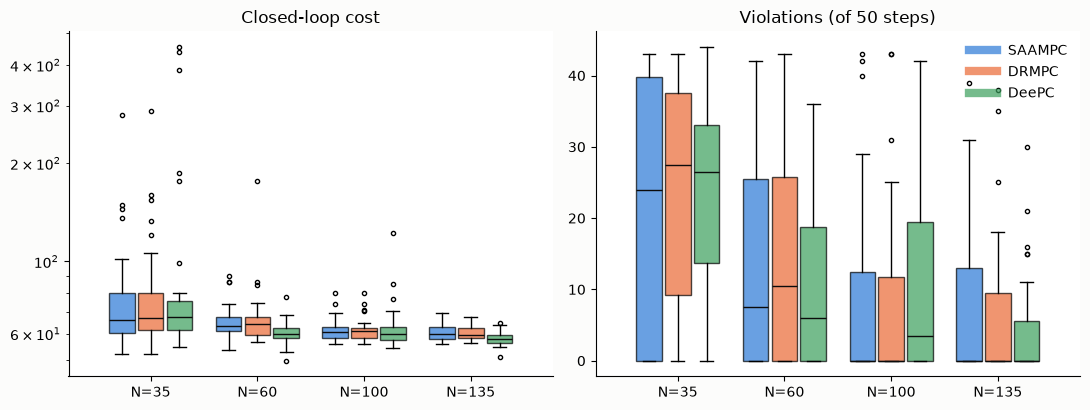

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), facecolor="#fcfcfb")
positions = np.arange(len(SIZES))
for ax, column, title in [(axes[0], 0, "Closed-loop cost"), (axes[1], 1, f"Violations (of {STEPS} steps)")]:
    for k, name in enumerate(COLORS):
        data = [results[N][name][:, column] for N in SIZES]
        data = [d[~np.isnan(d)] for d in data]
        box = ax.boxplot(data, positions=positions + (k - 1) * 0.27, widths=0.24, patch_artist=True,
                         medianprops=dict(color="#0b0b0b"), flierprops=dict(markersize=3))
        for patch in box["boxes"]:
            patch.set(facecolor=COLORS[name], alpha=0.7)
        ax.plot([], [], color=COLORS[name], linewidth=6, alpha=0.7, label=name)
    ax.set_xticks(positions, [f"N={N}" for N in SIZES])
    ax.set_title(title)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_yscale("log")
axes[1].legend(frameon=False)
fig.tight_layout()
plt.show()

## Head to head: who won each trial

Each trial gives all methods the same data and noise, so comparing **within** a trial cancels the luck of the draw (common random numbers): Var(A − B) = Var(A) + Var(B) − 2 Cov(A, B), and shared noise makes Cov(A, B) large.

**Sign test.** For each trial, record whether DeePC did better, worse, or tied, and drop the ties. If the methods were equally good, better/worse would be a fair coin flip. The p-value says how surprising the observed split is under that coin flip. It ignores how *much* better, so it is robust to the pile of zero-violation trials.

**Thresholds.** The earlier pre-registered criterion was p < 0.025 at N = 135 (2 tests). A claim across all N runs 8 violation tests (4 N × 2 opponents), so the Bonferroni threshold is 0.05 / 8 ≈ 0.006. Running more tests gives more chances of a fluke.

In [8]:
from math import comb


def sign_test(better, worse):
    """Two-sided exact p-value that better/worse is a fair coin flip (ties already dropped)."""
    k, total = min(better, worse), better + worse
    return min(1.0, 2 * sum(comb(total, i) for i in range(k + 1)) / 2**total) if total else 1.0


OPPONENTS = ("SAAMPC", "DRMPC")
METRICS = {0: "cost", 1: "violations"}
head_to_head = {}  # (N, opponent, column) -> (DeePC better, tie, DeePC worse, p)
for N in SIZES:
    for other in OPPONENTS:
        for column in METRICS:
            d = results[N]["DeePC"][:, column] - results[N][other][:, column]
            d = d[~np.isnan(d)]
            better, tie, worse = np.sum(d < 0), np.sum(d == 0), np.sum(d > 0)
            head_to_head[N, other, column] = (better, tie, worse, sign_test(better, worse))

print("DeePC vs. opponent, per trial: better / tie / worse (sign test p)")
for N in SIZES:
    cells = []
    for other in OPPONENTS:
        for column, label in METRICS.items():
            b, t, w, p = head_to_head[N, other, column]
            cells.append(f"{label} vs {other}: {b:>2}/{t:>2}/{w:>2} (p={p:.3f})")
    print(f"N={N:<3} | " + " | ".join(cells))

DeePC vs. opponent, per trial: better / tie / worse (sign test p)
N=35  | cost vs SAAMPC: 13/ 0/17 (p=0.585) | violations vs SAAMPC: 10/ 6/14 (p=0.541) | cost vs DRMPC: 15/ 0/15 (p=1.000) | violations vs DRMPC: 16/ 2/12 (p=0.572)
N=60  | cost vs SAAMPC: 21/ 0/ 9 (p=0.043) | violations vs SAAMPC: 12/ 5/13 (p=1.000) | cost vs DRMPC: 19/ 0/11 (p=0.200) | violations vs DRMPC: 15/ 4/11 (p=0.557)
N=100 | cost vs SAAMPC: 14/ 0/16 (p=0.856) | violations vs SAAMPC:  8/ 8/14 (p=0.286) | cost vs DRMPC: 14/ 0/16 (p=0.856) | violations vs DRMPC: 11/ 7/12 (p=1.000)
N=135 | cost vs SAAMPC: 21/ 0/ 9 (p=0.043) | violations vs SAAMPC: 12/14/ 4 (p=0.077) | cost vs DRMPC: 22/ 0/ 8 (p=0.016) | violations vs DRMPC: 11/15/ 4 (p=0.118)


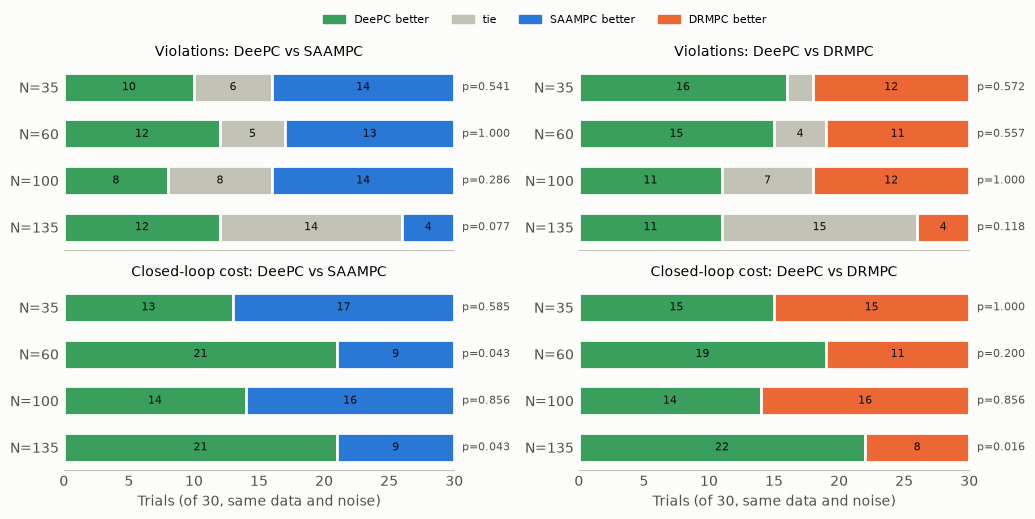

In [9]:
SURFACE, TIE, INK, MUTED = "#fcfcfb", "#c3c2b7", "#0b0b0b", "#52514e"
fig, axes = plt.subplots(2, 2, figsize=(11, 5.2), sharex=True, facecolor=SURFACE)
rows = [(1, "Violations"), (0, "Closed-loop cost")]
y = np.arange(len(SIZES))[::-1]  # N = 35 on top

for r, (column, metric) in enumerate(rows):
    for c, other in enumerate(OPPONENTS):
        ax = axes[r, c]
        ax.set_facecolor(SURFACE)
        for yi, N in zip(y, SIZES):
            better, tie, worse, p = head_to_head[N, other, column]
            left = 0
            for count, color in [(better, COLORS["DeePC"]), (tie, TIE), (worse, COLORS[other])]:
                if count:
                    ax.barh(yi, count, left=left, height=0.62, color=color, edgecolor=SURFACE, linewidth=2)
                    if count >= 3:
                        ax.text(left + count / 2, yi, str(count), ha="center", va="center", fontsize=8, color=INK)
                left += count
            ax.text(TRIALS * 1.02, yi, f"p={p:.3f}", va="center", fontsize=8, color=MUTED)
        ax.set_yticks(y, [f"N={N}" for N in SIZES])
        ax.set_xlim(0, TRIALS)
        ax.set_title(f"{metric}: DeePC vs {other}", fontsize=10)
        ax.tick_params(length=0, colors=MUTED)
        ax.spines[["top", "right", "left"]].set_visible(False)
        ax.spines["bottom"].set_color(TIE)
for ax in axes[-1]:
    ax.set_xlabel(f"Trials (of {TRIALS}, same data and noise)", color=MUTED)

legend = {"DeePC better": COLORS["DeePC"], "tie": TIE,
          "SAAMPC better": COLORS["SAAMPC"], "DRMPC better": COLORS["DRMPC"]}
fig.legend([plt.Rectangle((0, 0), 1, 1, color=v) for v in legend.values()], legend.keys(),
           loc="upper center", ncol=4, frameon=False, fontsize=8, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 0.95, 0.95))
plt.show()

## Conclusions

To be written after running the notebook.